In [1]:
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer as wnl
from nltk.corpus import stopwords
import re
import matplotlib.pyplot as plt
import numpy as np
from scipy.stats import pearsonr
from nltk.stem.snowball import SnowballStemmer
from nltk.corpus import wordnet as wn

# Task 1-3

The Lamb tf-idf: PearsonRResult(statistic=np.float64(0.059836923226402286), pvalue=np.float64(0.6703893899488448))
The Tiger tf-idf: PearsonRResult(statistic=np.float64(-0.29366901520663186), pvalue=np.float64(0.01167991910825954))


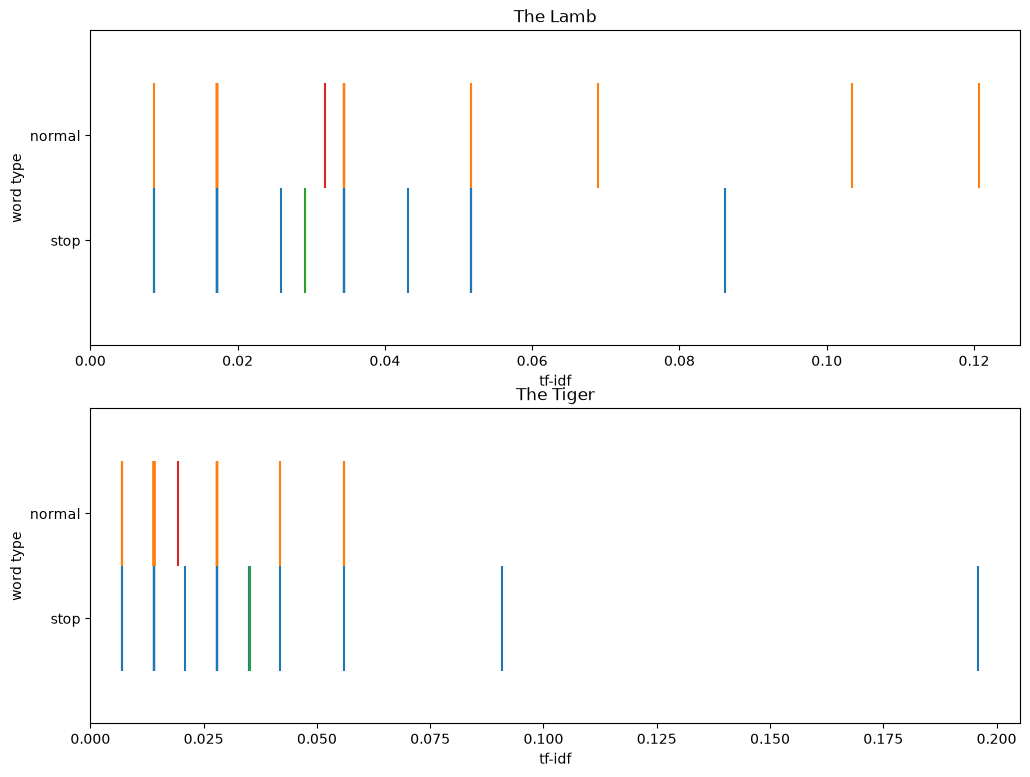

The Lamb tf-ent: PearsonRResult(statistic=np.float64(0.12762895659934295), pvalue=np.float64(0.36243815937049684))
The Tiger tf-ent: PearsonRResult(statistic=np.float64(-0.2880850763051803), pvalue=np.float64(0.013452569507822155))


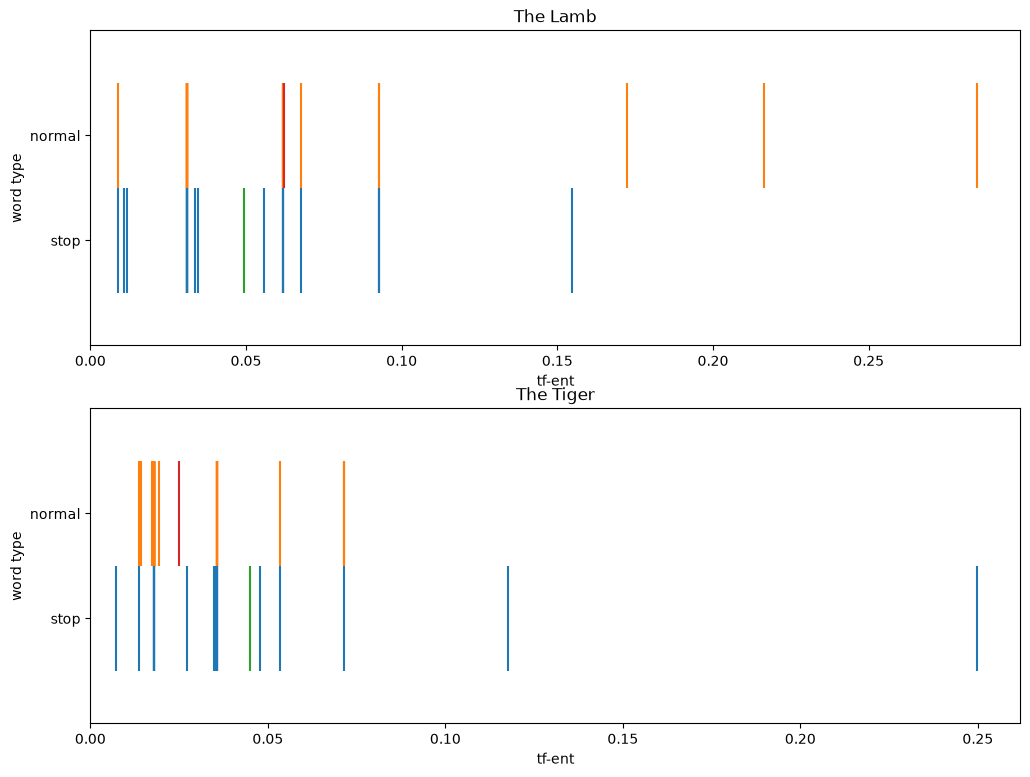

The Lamb bm-idf: PearsonRResult(statistic=np.float64(0.056247382237928335), pvalue=np.float64(0.6891272254012208))
The Tiger bm-idf: PearsonRResult(statistic=np.float64(-0.29355033265960967), pvalue=np.float64(0.011715374554890828))


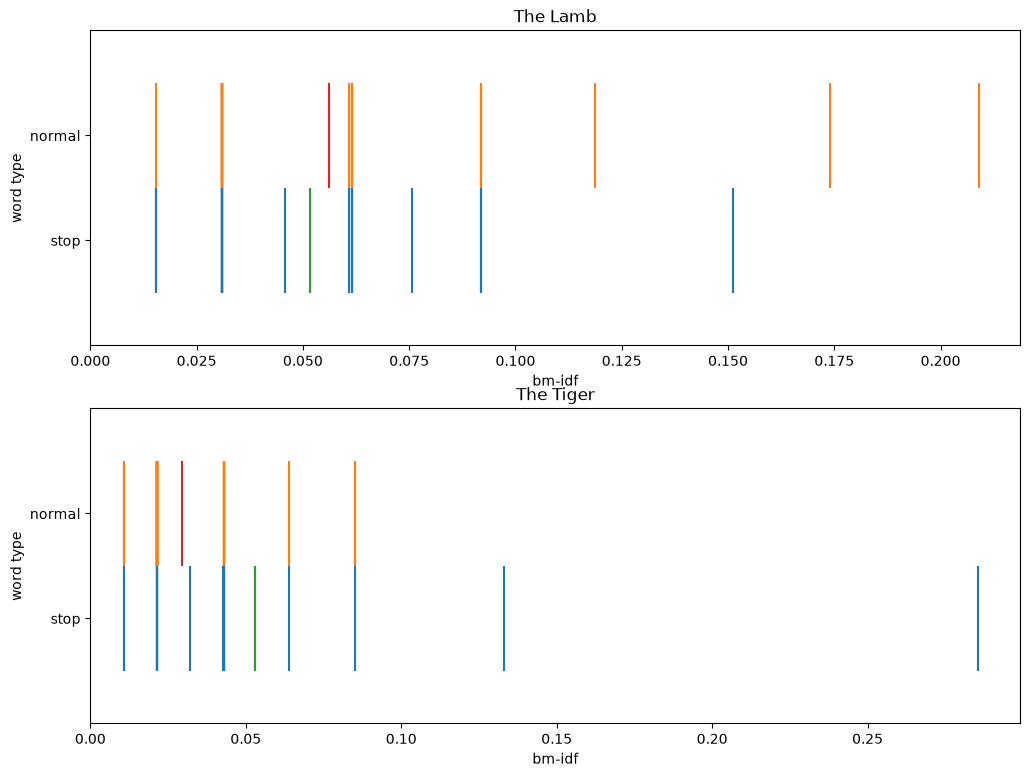

The Lamb bm-ent: PearsonRResult(statistic=np.float64(0.12580117906179863), pvalue=np.float64(0.3694090090649118))
The Tiger bm-ent: PearsonRResult(statistic=np.float64(-0.28778280872228174), pvalue=np.float64(0.013554830714260186))


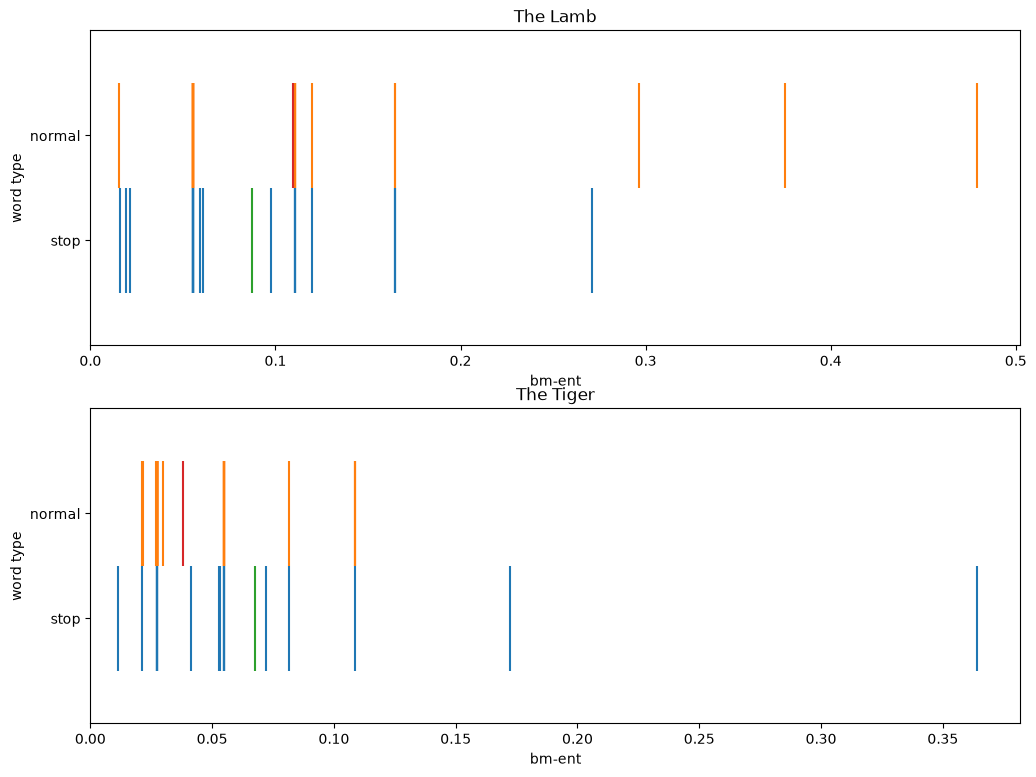

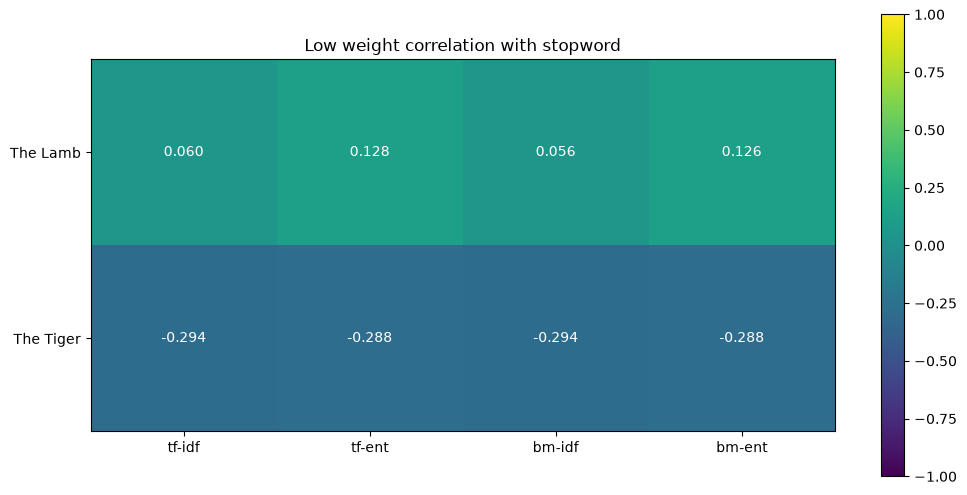

Done


In [2]:
poems = {
	"The Lamb": "./poems/thelamb.txt",
	"The Tiger": "./poems/thetiger.txt",
}

# Tokenization
documents = []
features = []

for key in poems.keys():
	file = open(poems[key], "r")
	tokens = [token.lower() for token in word_tokenize(file.read()) if token.isalpha()]
	documents.append(tokens)
	features.extend(tokens)


# Remove duplicates and sort
features = sorted(list(set(features)))


# Calculating tf-idf and bm25 scores
def calculate_scores(documents, features):
	N = len(documents)
	M = len(features)

	tf_scores = np.zeros((N, M))
	bm25_scores = np.zeros((N, M))
	idf_scores = np.zeros((M))
	ent_scores = np.zeros((M))

	k_1 = 1.5
	b = 0.75
	gl = sum([len(d) for d in documents])
	avgdl = gl / N

	for x in range(M):
		term = features[x]
		df = 0
		gf = 0

		for d in documents:
			df += 1 if term in d else 0
			gf += d.count(term)
		gf /= gl
		
		idf = 1 + np.log2(N / df)
		ent = 0
		
		idf_scores[x] = idf

		for y in range(N):
			tf = documents[y].count(term) / len(documents[y])
			ent += (tf / gf) * np.log2(tf / gf) if tf else 0
			tf_scores[y][x] = tf
			bm25_scores[y][x] = tf * (k_1 + 1) / (tf + k_1 * (1 - b + b * (len(documents[y]) / avgdl)))

		ent = ent / np.log2(N) + 1.0
		ent_scores[x] = ent

	
	return tf_scores, bm25_scores, idf_scores, ent_scores

tf_scores, bm25_scores, idf_scores, ent_scores = calculate_scores(documents, features)


stop_list = [SnowballStemmer("english").stem(feature) in stopwords.words() for feature in features]



def plot_locglo(local_weight, global_weight, stops, name=""):
	N, M = np.shape(local_weight)

	fig, ax = plt.subplots(N, 1)
	fig.set_size_inches(12, 9)

	data = np.zeros((N, M))
	for n in range(N):
		for m in range(M):
			data[n][m] = local_weight[n][m] * global_weight[m]
	
	correlations = []

	for i in range(N):
		data_stops = [data[i][j] for j in range(M) if stops[j] and data[i][j] != 0.0]
		data_normal = [data[i][j] for j in range(M) if not stops[j] and data[i][j] != 0.0]
		
		data_x = data_stops + data_normal
		data_y = [0 for _ in range(len(data_stops))] + [1 for _ in range(len(data_normal))]
		cor = pearsonr(data_x, data_y)
		correlations.append(cor.statistic)
		print(f"{list(poems)[i]} {name}: {cor}")

		ax[i].eventplot([data_stops, data_normal], lineoffsets=[1, 2], colors=['tab:blue', 'tab:orange'])
		ax[i].eventplot([[np.mean(data_stops)], [np.mean(data_normal)]], lineoffsets=[1, 2], colors=['tab:green', 'tab:red'])
		ax[i].set(
			title=list(poems)[i],
			xlabel=name,
			ylabel="word type",
			xlim=(0, None),
			ylim=(0, 3),
			yticks=np.arange(1, 3),
			yticklabels=["stop", "normal"]
		)

	# Calculate pearsonr

	plt.show()
	plt.close()

	return correlations


# Plot scores
cors = np.transpose([
	plot_locglo(tf_scores, idf_scores, stop_list, "tf-idf"),
	plot_locglo(tf_scores, ent_scores, stop_list, "tf-ent"),
	plot_locglo(bm25_scores, idf_scores, stop_list, "bm-idf"),
	plot_locglo(bm25_scores, ent_scores, stop_list, "bm-ent")
])




names = list(poems)
types = ["tf-idf", "tf-ent", "bm-idf", "bm-ent"]


fig, ax = plt.subplots()
fig.set_size_inches(12, 6)
im = ax.imshow(cors, cmap='viridis', vmin=-1.0, vmax=1.0)
ax.set(
	title="Low weight correlation with stopword",
	xticks=range(len(types)),
	xticklabels=types,
	yticks=range(len(names)),
	yticklabels=names
)

ax.figure.colorbar(im, ax=ax)

for i in range(len(names)):
	for j in range(len(types)):
		text = ax.text(j, i, f"{cors[i, j]:.03f}", ha="center", va="center", color="w")

plt.show()
plt.close()


print("Done")

154 3041
[np.float64(0.04802573600293018), np.float64(0.8060113971634091), np.float64(0.07959408559743911), np.float64(1.3391864263756426)]


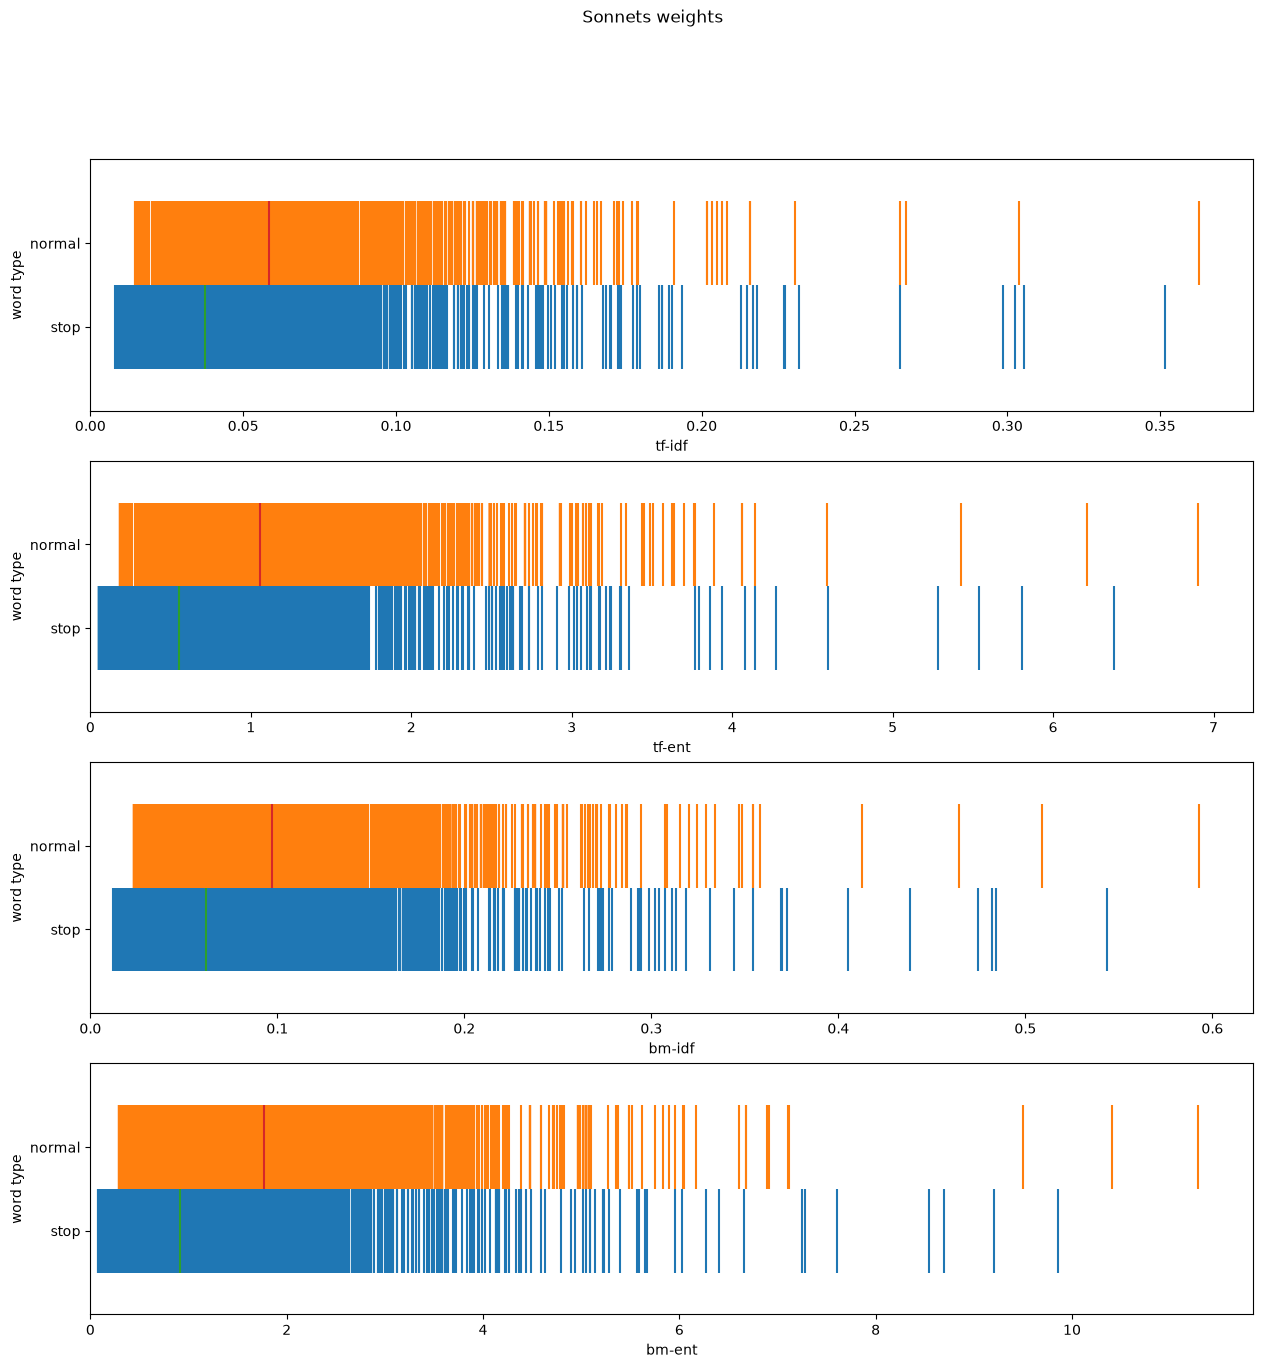

tf-idf
acc	0.735433197082632
pre	0.7007031488841333

tf-ent
acc	0.7670113007934599
pre	0.7290655339805825

bm-idf
acc	0.7369559990382304
pre	0.7006524047944166

bm-ent
acc	0.7649274665384307
pre	0.7244377811094452

tf-idf mean correlation: 0.432
tf-ent mean correlation: 0.519
bm-idf mean correlation: 0.440
bm-ent mean correlation: 0.524


/tmp/ipykernel_42314/2866796135.py:217: UserWarning: Adding colorbar to a different Figure <Figure size 1200x600 with 2 Axes> than <Figure size 2500x500 with 2 Axes> which fig.colorbar is called on.
  ax.figure.colorbar(im, ax=ax)


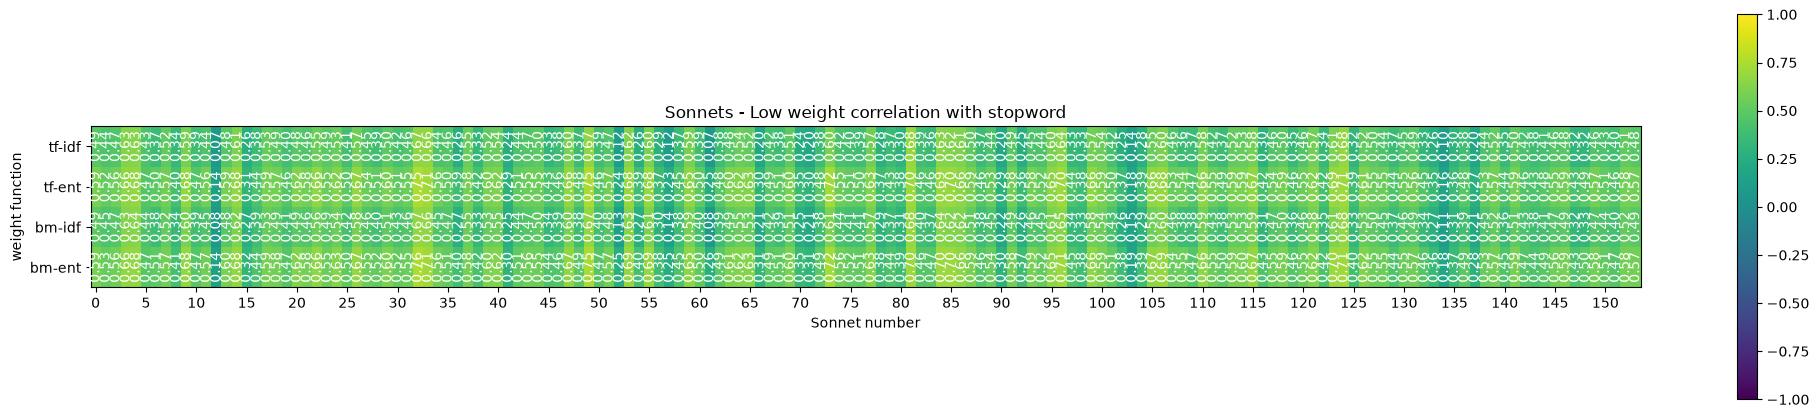

In [3]:
def calculate_scores(documents, features):
	N = len(documents)
	M = len(features)

	tf_scores = np.zeros((N, M))
	bm25_scores = np.zeros((N, M))
	idf_scores = np.zeros((M))
	ent_scores = np.zeros((M))

	k_1 = 1.5
	b = 0.75
	gl = sum([len(d) for d in documents])
	avgdl = gl / N

	for x in range(M):
		term = features[x]
		df = 0
		gf = 0

		for d in documents:
			df += 1 if term in d else 0
			gf += d.count(term)
		gf /= gl
		
		idf = 1 + np.log2(N / df)
		ent = 0
		
		idf_scores[x] = idf

		for y in range(N):
			tf = documents[y].count(term) / len(documents[y])
			ent += (tf / gf) * np.log2(tf / gf) if tf else 0
			tf_scores[y][x] = tf
			bm25_scores[y][x] = tf * (k_1 + 1) / (tf + k_1 * (1 - b + b * (len(documents[y]) / avgdl)))

		ent = ent / np.log2(N) + 1.0
		ent_scores[x] = ent

	
	return tf_scores, bm25_scores, idf_scores, ent_scores

def sonnets_correlations(local_weight, global_weight, stops):
	N, M = np.shape(local_weight)

	data = np.zeros((N, M))
	for n in range(N):
		for m in range(M):
			data[n][m] = local_weight[n][m] * global_weight[m]
	
	correlations = []

	for i in range(N):
		data_stops = [data[i][j] for j in range(M) if stops[j] and data[i][j] != 0.0]
		data_normal = [data[i][j] for j in range(M) if not stops[j] and data[i][j] != 0.0]
		
		data_x = data_stops + data_normal
		data_y = [0 for _ in range(len(data_stops))] + [1 for _ in range(len(data_normal))]
		cor = pearsonr(data_x, data_y)
		correlations.append(cor.statistic)

	return correlations

sonnet_max = 154

# Analyze sonnets for stopword recognition, where each sonnet is regarded as its own document
sonnets_regex = r"[\d]+\n\n([\D]+).+" * 154

file = open("./poems/sonnets.txt")
sonnets_raw = file.read()
sonnets = re.search(sonnets_regex, sonnets_raw).groups()

documents = []
features = []
for sonnet in sonnets:
	tokens = [token.lower() for token in word_tokenize(sonnet) if token.isalpha()]
	documents.append(tokens)
	features.extend(tokens)
	if len(documents) == sonnet_max:
		break

features = sorted(list(set(features)))
stop_list = [SnowballStemmer("english").stem(feature) in stopwords.words() for feature in features]

tf_scores, bm25_scores, idf_scores, ent_scores = calculate_scores(documents, features)


N, M = np.shape(tf_scores)
print(N, M)

tf_idf_stop = [ ]
tf_ent_stop = [ ]
bm_idf_stop = [ ]
bm_ent_stop = [ ]

tf_idf_norm = [ ]
tf_ent_norm = [ ]
bm_idf_norm = [ ]
bm_ent_norm = [ ]

for n in range(N):
	for m in range(M):
		if stop_list[m]:
			tf_idf_stop.append(tf_scores[n][m] * idf_scores[m])
			tf_ent_stop.append(tf_scores[n][m] * ent_scores[m])
			bm_idf_stop.append(bm25_scores[n][m] * idf_scores[m])
			bm_ent_stop.append(bm25_scores[n][m] * ent_scores[m])
		else:
			tf_idf_norm.append(tf_scores[n][m] * idf_scores[m])
			tf_ent_norm.append(tf_scores[n][m] * ent_scores[m])
			bm_idf_norm.append(bm25_scores[n][m] * idf_scores[m])
			bm_ent_norm.append(bm25_scores[n][m] * ent_scores[m])



combined_stop = [
	tf_idf_stop,
	tf_ent_stop,
	bm_idf_stop,
	bm_ent_stop
]

combined_norm = [
	tf_idf_norm,
	tf_ent_norm,
	bm_idf_norm,
	bm_ent_norm
]


types = ["tf-idf", "tf-ent", "bm-idf", "bm-ent"]
fig, ax = plt.subplots(4, 1)
fig.set_size_inches(15, 15)
fig.suptitle("Sonnets weights") 

mean_of_means = []

for i in range(4):
	data_stops = [data for data in combined_stop[i] if data != 0.0]
	data_normal = [data for data in combined_norm[i] if data != 0.0]
	mean = [[np.mean(data_stops)], [np.mean(data_normal)]]
	mean_of_means.append((mean[0][0] + mean[1][0]) / 2)

	ax[i].eventplot([data_stops, data_normal], lineoffsets=[1, 2], colors=['tab:blue', 'tab:orange'])
	ax[i].eventplot(mean, lineoffsets=[1, 2], colors=['tab:green', 'tab:red'])
	ax[i].set(
		xlabel=types[i],
		ylabel="word type",
		xlim=(0, None),
		ylim=(0, 3),
		yticks=np.arange(1, 3),
		yticklabels=["stop", "normal"]
	)

print(mean_of_means)
plt.show()
plt.close()


for i in range(4):
	tp = 0
	tn = 0
	fp = 0
	fn = 0
	for n in range(len(combined_stop[i])):
		if combined_stop[i][n] == 0:
			pass
		elif combined_stop[i][n] <= mean_of_means[i]:
			tp += 1
		else:
			fn += 1
	for n in range(len(combined_norm[i])):
		if combined_norm[i][n] == 0:
			pass
		elif combined_norm[i][n] > mean_of_means[i]:
			tn += 1
		else:
			fp += 1
	
	print(f"{types[i]}\nacc\t{(tp+tn)/(tp+tn+fn+fp)}\npre\t{tp/(tp+fp)}\n")




# Plot scores
cors = np.array([
	sonnets_correlations(tf_scores, idf_scores, stop_list),
	sonnets_correlations(tf_scores, ent_scores, stop_list),
	sonnets_correlations(bm25_scores, idf_scores, stop_list),
	sonnets_correlations(bm25_scores, ent_scores, stop_list)
])





names = len(documents)
types = ["tf-idf", "tf-ent", "bm-idf", "bm-ent"]

for i in range(len(cors)):
	avg = sum(cors[i]) / len(cors[i])
	print(f"{types[i]} mean correlation: {avg:.03f}")


fig, ax = plt.subplots()
fig.set_size_inches(25, 5)
ax.imshow(cors, cmap='viridis', vmin=-1.0, vmax=1.0)
ax.set(
	title="Sonnets - Low weight correlation with stopword",
	xlabel="Sonnet number",
	ylabel="weight function",
	yticks=range(len(types)),
	yticklabels=types,
	xticks=range(0, names, 5),
	aspect=4
)

ax.figure.colorbar(im, ax=ax)

for j in range(names):
	for i in range(len(types)):
		text = ax.text(j, i, f"{cors[i, j]:.02f}", ha="center", va="center", color="w", rotation=90)

plt.show()
plt.close()


# Task 10

In [4]:
def calculate_scores(documents, features):
	N = len(documents)
	M = len(features)

	tf_scores = np.zeros((N, M))
	bm25_scores = np.zeros((N, M))
	idf_scores = np.zeros((M))
	ent_scores = np.zeros((M))

	k_1 = 1.5
	b = 0.75
	gl = sum([len(d) for d in documents])
	avgdl = gl / N

	for x in range(M):
		term = features[x]
		df = 0
		gf = 0

		for d in documents:
			df += 1 if term in d else 0
			gf += d.count(term)
		gf /= gl
		
		idf = 1 + np.log2(N / df)
		ent = 0
		
		idf_scores[x] = idf

		for y in range(N):
			tf = documents[y].count(term) / len(documents[y])
			ent += (tf / gf) * np.log2(tf / gf) if tf else 0
			tf_scores[y][x] = tf
			bm25_scores[y][x] = tf * (k_1 + 1) / (tf + k_1 * (1 - b + b * (len(documents[y]) / avgdl)))

		ent = ent / np.log2(N) + 1.0
		ent_scores[x] = ent

	
	return tf_scores, bm25_scores, idf_scores, ent_scores

def wn_link(word1, lang1, word2, lang2):
	synsets1 = wn.synsets(word1, lang=lang1)
	synsets2 = wn.synsets(word2, lang=lang2)

	set1 = set(synsets1)
	set2 = set(synsets2)

	common_synsets = set1.intersection(set2)
	return len(common_synsets) > 0


def get_score(scores, key, m, n, weight_type="tf-ent"):

	tf_scores, bm25_scores, idf_scores, ent_scores = scores[key]
	match weight_type:
		case "tf-idf":
			return tf_scores[n][m] * idf_scores[m]
		case "tf-ent":
			return tf_scores[n][m] * ent_scores[m]
		case "bm-idf":
			return bm_scores[n][m] * idf_scores[m]
		case "bm-ent":
			return bm_scores[n][m] * ent_scores[m]




poems = [
	("The Lamb", "./poems/thelamb.txt", "english"),
	("The Tiger", "./poems/thetiger.txt", "english"),
	("Sonnets", "./poems/sonnets.txt", "english"),

	("Ensimmainen lempi", "./poems/ensimmainenlempi.txt", "finnish"),
	("Oli mulla kulta kaunoinen", "./poems/olimullakultakaunoinen.txt", "finnish"),

	("La Vita Solitaria", "./poems/lavitasolitaria.txt", "italian"),
	("A Silvia", "./poems/asilvia.txt", "italian")
]


documents = {}
features = {}
langs = list(set([lang for _, _, lang in poems]))

for name, path, lang in poems:
	documents[lang] = []
	features[lang] = []

for name, path, lang in poems:
	file = open(path, "r")
	tokens = [token.lower() for token in word_tokenize(file.read()) if token.isalpha()]
	documents[lang].append(tokens)
	features[lang].extend(tokens)

for key in langs:
	features[key] = sorted(list(set(features[key])))
	print(f"{key}: {len(features[key])}")


scores = {}
for key in langs:
	scores[key] = (calculate_scores(documents[key], features[key]))


stop_list = {}
for lang in langs:
	stop_list[lang] = [SnowballStemmer(lang).stem(feature) in stopwords.words(lang) for feature in features[lang]]
	print(f"{lang}: stops {stop_list[lang].count(True) / len(features[lang]):.02f}")


for i in range(len(langs) - 1):
	for j in range(i + 1, len(langs)):
		lang1 = langs[i]
		lang2 = langs[j]
		
		both_stops = []
		both_normal = []
		different = []

		shape1 = np.shape(scores[lang1][0])
		shape2 = np.shape(scores[lang2][0])

		for u1 in range(len(features[lang1])):
			for u2 in range(len(features[lang2])):

				lang1_feature = features[lang1][u1]
				lang2_feature = features[lang2][u2]

				lang1_stop = stop_list[lang1][u1]
				lang2_stop = stop_list[lang2][u2]

				if wn_link(lang1_feature, lang1[0:3], lang2_feature, lang2[0:3]):
					sum1 = [get_score(scores, lang1, u1, m) for m in range(len(documents[lang1]))]
					sum2 = [get_score(scores, lang2, u2, m) for m in range(len(documents[lang2]))]
					avg1 = sum(sum1) / len(documents[lang1])
					avg2 = sum(sum2) / len(documents[lang2])
					if lang1_stop and lang2_stop:
						both_stops.append((lang1_feature, lang2_feature, avg1, avg2))
					elif not lang1_stop and not lang1_stop:
						both_normal.append((lang1_feature, lang2_feature, avg1, avg2))
					else: 
						different.append((lang1_feature, lang2_feature, avg1, avg2))

		spt = sum([[a, b] for _, _, a, b in both_stops], [])
		npt = sum([[a, b] for _, _, a, b in both_normal], [])
		mpt = sum([[a, b] for _, _, a, b in different], [])
		spt = spt if bool(spt) else [0]
		npt = npt if bool(npt) else [0]
		mpt = mpt if bool(mpt) else [0]

		stop_plot = [np.mean(spt), np.std(spt), max(spt), min(spt)]
		normal_plot = [np.mean(npt), np.std(npt), max(npt), min(npt)]
		mixed_plot = [np.mean(mpt), np.std(mpt), max(mpt), min(mpt)]



		print(lang1, lang2)
		print("\tCount\tMean\t\tStd\t\tMax\t\tMin")
		print(f"Stop:\t{len(both_stops)}\t{stop_plot[0]:.3e}\t{stop_plot[1]:.3e}\t{stop_plot[2]:.3e}\t{stop_plot[3]:.3e}")
		print(f"Normal:\t{len(both_normal)}\t{normal_plot[0]:.3e}\t{normal_plot[1]:.3e}\t{normal_plot[2]:.3e}\t{normal_plot[3]:.3e}")
		print(f"Mixed:\t{len(different)}\t{mixed_plot[0]:.3e}\t{mixed_plot[1]:.3e}\t{mixed_plot[2]:.3e}\t{mixed_plot[3]:.3e}\n")
	



italian: 551
finnish: 344
english: 3081
italian: stops 0.12
finnish: stops 0.04
english: stops 0.04
italian finnish
	Count	Mean		Std		Max		Min
Stop:	0	0.000e+00	0.000e+00	0.000e+00	0.000e+00
Normal:	27	1.434e-02	2.010e-02	8.758e-02	1.315e-03
Mixed:	1	2.321e-02	2.058e-02	4.379e-02	2.630e-03

italian english
	Count	Mean		Std		Max		Min
Stop:	11	4.837e-03	6.310e-03	2.004e-02	7.598e-05
Normal:	452	3.384e-02	5.077e-01	1.066e+01	1.899e-05
Mixed:	12	7.586e-03	1.229e-02	5.467e-02	1.899e-05

finnish english
	Count	Mean		Std		Max		Min
Stop:	4	2.693e-03	3.294e-03	1.108e-02	9.497e-05
Normal:	266	3.505e-02	2.081e-01	2.056e+00	1.899e-05
Mixed:	3	9.540e-03	1.580e-02	4.379e-02	1.899e-05

